# Домашняя работа №7
Мацюк Константин Владимирович  
НПИбд-02-25  
1032253640

Линейные дифференциальные уравнения с постоянными коэффициентами.

Ядро: **SageMath**. Код `gauss.sage` и используемые части `fdm` включены в notebook.
Ячейки SageMath не запускались в среде подготовки отчёта. Сохранённые иллюстрации и численные оценки проверены независимым расчётом RK4; формулы также сверены с матричной экспонентой. При запуске ячеек графики и сравнение пересчитываются в SageMath/fdm.

In [ ]:
from sage.all import *
t, mu = var('t mu')
assume(t, 'real')

### Метод Гаусса из приложенного файла

In [ ]:
# Gauss, ver. 2.1
def triangulation(S):
    T=[]
    while S!=[]:
        m=max([s.lm() for s in S])
        L = [s for s in S if s.lm() == m]
        S = [s for s in S if s.lm() < m]
        g1=L[0]
        T.append(g1)
        for g in L[1:]:
            g=g1.lc()*g-g.lc()*g1
            if g!=0:
                S.append(g)
        D=[s for s in S if s.degree()==0]
        if D!=[]:
            T=D
            break
    return T
    
def tsolve(T):
    T.reverse()
    D={}
    while T!=[]:
        g=T[0]
        D[g.lm()] = -(g-g.lt())/g.lc()
        T=[t.subs(D) for t in T[1:]]
    return D

## Задание 1
Напишите свою функцию для решения задачи Коши для однородного линейного дифференциального уравнения с постоянными коэффициентами. На входе оператор $P$ и список значений $x$ и производных при $t=0$. На выходе решение $x$ как символьное выражение, содержащее $t$ и комплексные константы.

Коэффициенты и начальные данные представляются в `QQbar`, как в лекции (точные алгебраические числа).

In [ ]:
def cauchy_data(P, values):
    R = PolynomialRing(QQbar, 'mu')
    p = R(SR(P(exp(mu*t))*exp(-mu*t)).expand())
    n = p.degree()
    if len(values) != n:
        raise ValueError('Число начальных условий должно совпадать с порядком ОДУ.')
    basis = [(a,j) for a,m in p.roots() for j in range(m)]
    K = PolynomialRing(QQbar, names=['c'+str(i) for i in range(n)])
    c = K.gens()
    equations = []
    for k in range(n):
        # Производная t^j*exp(a*t) порядка k в нуле.
        eq = sum(c[i]*factorial(k)/factorial(k-j)*a**(k-j)
                 for i,(a,j) in enumerate(basis) if j <= k)-K(values[k])
        equations.append(K(eq))
    answer = tsolve(triangulation(equations))
    coefficients = [QQbar(ci.subs(answer)) for ci in c]
    return p, basis, coefficients

def cauchy_complex(P, values):
    p, basis, coefficients = cauchy_data(P, values)
    return sum(SR(c.radical_expression())*t**j*
               exp(SR(a.radical_expression())*t)
               for (a,j),c in zip(basis,coefficients))

In [ ]:
P0 = lambda f: diff(f,t,2)+3*f
show(cauchy_complex(P0,[2,1]))

Ответ для примера:
$$
x(t)=\left(1-\frac{i}{2\sqrt3}\right)e^{i\sqrt3t}
+\left(1+\frac{i}{2\sqrt3}\right)e^{-i\sqrt3t}.
$$

## Задание 2
Модифицируйте функцию так, чтобы при вещественных данных она давала выражение, не содержащее комплексные константы.

In [ ]:
def real_constant(a):
    value = QQbar(a)
    expr = SR(value.radical_expression())
    # В неприводимых кубических радикалах может появляться I.
    # В таком случае сохраняем точное вещественное алгебраическое число.
    return SR(AA(value)) if expr.has(I) else expr

def cauchy(P, values):
    p, basis, coefficients = cauchy_data(P, values)
    if any(a.imag() != 0 for a in p.list()) or any(QQbar(v).imag() != 0 for v in values):
        return cauchy_complex(P, values)
    result = SR(0)
    for (a,j),c in zip(basis,coefficients):
        alpha = real_constant(a.real())
        if a.imag() == 0:
            result += real_constant(c.real())*t**j*exp(alpha*t)
        elif a.imag() > 0:
            beta = real_constant(a.imag())
            u = real_constant(c.real())
            v = real_constant(c.imag())
            result += 2*t**j*exp(alpha*t)*(u*cos(beta*t)-v*sin(beta*t))
    return result

In [ ]:
show(cauchy(P0,[2,1]))

Ответ:
$$x(t)=2\cos(\sqrt3t)+\frac{1}{\sqrt3}\sin(\sqrt3t).$$

## Задание 3
Протестируйте свою функцию на следующих примерах:

а) $x''-3x=0$, $x(0)=2$, $x'(0)=1$;

б) $x''+3x=0$, $x(0)=2$, $x'(0)=1$;

в) $x''+x'+3x=0$, $x(0)=2$, $x'(0)=1$;

г) $x''+2x'+x=0$, $x(0)=2$, $x'(0)=1$;

д) $x'''+3x=0$, $x(0)=2$, $x'(0)=1$, $x''(0)=0$;

е) $x^{(9)}+x=0$, $x(0)=1$, а все производные вплоть до восьмого порядка равны нулю.

In [ ]:
operators = [
    lambda f: diff(f,t,2)-3*f,
    lambda f: diff(f,t,2)+3*f,
    lambda f: diff(f,t,2)+diff(f,t)+3*f,
    lambda f: diff(f,t,2)+2*diff(f,t)+f,
    lambda f: diff(f,t,3)+3*f,
    lambda f: diff(f,t,9)+f
]
initials = [[2,1],[2,1],[2,1],[2,1],[2,1,0],[1]+[0]*8]
labels = ['а','б','в','г','д','е']
solutions = [cauchy(P,u0) for P,u0 in zip(operators,initials)]
for label,F in zip(labels,solutions):
    print(label+')')
    show(F)

Ответы (эквивалентные компактные формы):

$$x_а(t)=2\cosh(\sqrt3t)+\frac{\sinh(\sqrt3t)}{\sqrt3}.$$
$$x_б(t)=2\cos(\sqrt3t)+\frac{\sin(\sqrt3t)}{\sqrt3}.$$
$$x_в(t)=e^{-t/2}\left(2\cos\frac{\sqrt{11}t}{2}+\frac4{\sqrt{11}}\sin\frac{\sqrt{11}t}{2}\right).$$
$$x_г(t)=(2+3t)e^{-t}.$$
Для пункта д) положим $\rho=\sqrt[3]{3}$:
$$x_д(t)=\frac{2-1/\rho}{3}e^{-\rho t}
+e^{\rho t/2}\left(\frac{4+1/\rho}{3}\cos\frac{\sqrt3\rho t}{2}
+\frac1{\sqrt3\rho}\sin\frac{\sqrt3\rho t}{2}\right).$$
Для пункта е):
$$x_е(t)=\frac{e^{-t}}9+\frac29\sum_{k=0}^{3}
e^{t\cos\theta_k}\cos(t\sin\theta_k),\qquad
\theta_k=\frac{(2k+1)\pi}{9}.$$

Проверка решений по характеристическим корням и начальным условиям:

In [ ]:
for label,P,u0 in zip(labels,operators,initials):
    p, basis, coefficients = cauchy_data(P,u0)
    residuals = [p.derivative(k)(a) for a,j in basis for k in range(j+1)]
    data = [sum(c*factorial(k)/factorial(k-j)*a**(k-j)
                for (a,j),c in zip(basis,coefficients) if j <= k)
            for k in range(len(u0))]
    print(label, 'ОДУ:', all(v == 0 for v in residuals),
          'начальные условия:', data == list(map(QQbar,u0)))

Ожидаемый результат: для всех шести примеров `ОДУ: True`, `начальные условия: True`.

## Задание 4
Нарисуйте графики решений, полученных в предыдущем номере, на интервале $0<t<5$.

In [ ]:
graphs = [plot(F,(t,0,5),title=label+')',axes_labels=['t','x(t)'])
          for label,F in zip(labels,solutions)]
show(graphics_array(graphs,3,2),figsize=[12,10])

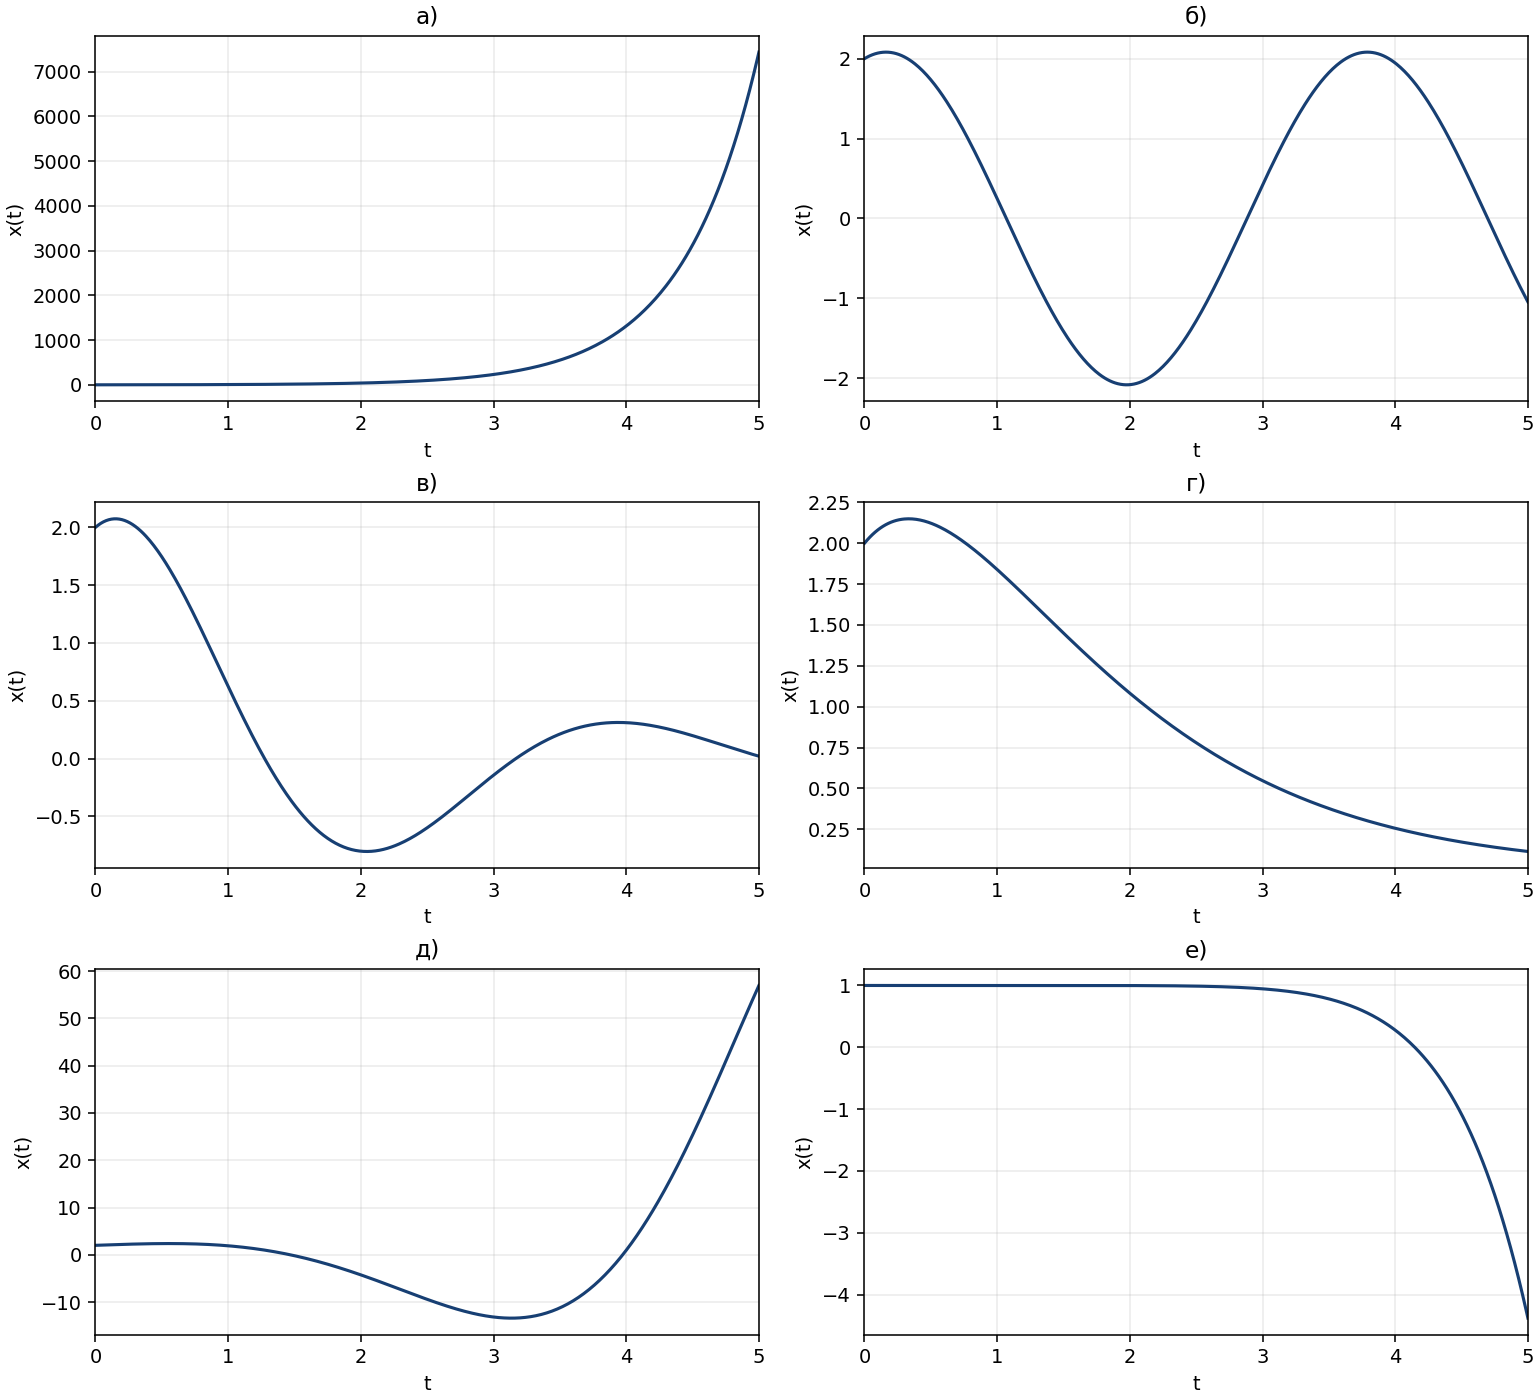

Вывод: в примере а) решение растёт; в б) колеблется с постоянной амплитудой; в в) колебания затухают; в г) решение стремится к нулю. В д) амплитуда колебаний растёт. В е) на данном интервале решение убывает и меняет знак.

## Задание 5
Нарисуйте графики приближенных решений начальных задач, рассмотренных в предыдущем номере, на интервале $0<t<5$ в системе `fdm` и сравните с графиками, полученными в предыдущем номере.

Используемые части `fdm` приведены в следующей свёрнутой ячейке. Расчёт выполняется стандартным явным методом Рунге — Кутты четвёртого порядка с $N=500$, $\Delta t=0.01$.

In [ ]:
# Используемые части fdm (malykhmd/fdm); тела методов сохранены.

class Initial_problem:
    def __init__(self, x, f, x0, T):
        self.f = f
        self.x = x
        self.x0 = x0
        self.T = T
    def list(self):
        if type(self.f)!=type([]):
            f=[self.f]
            x=[self.x]
            x0=[self.x0]
        else:
            f=self.f
            x=self.x
            x0=self.x0
        T=self.T
        return [f, x, x0, T]
    def subs(self, u, abc, field=False):
        [f,x,x0,T]=self.list()
        if len(abc)==len(x):
            S=[i==j for [i,j] in zip(x,abc)]
        else:
            S=[t==abc[0]]+[i==j for [i,j] in zip(x,abc[1:])]
        if type(u)==type([]): 
            if field==False:
                ans=[uu.subs(S) for uu in u]
            else:
                ans=[field(uu.subs(S)) for uu in u]            
        else:
            if field==False:
                ans=u.subs(S)
            else:
                ans=field(u.subs(S))
        return ans

class Numsol:
    def __init__(self, points, variables,h,order,problem):
        self.points = points
        self.variables = variables
        self.h = h
        self.order = order
        self.problem = problem
    def size(self):
        return len(self.points)
    def list(self):
        return self.points
    def plot(self, u, v, axes_labels='automatic', linestyle='solid', color='blue', points=False):
        S=[[x_==p_ for [x_,p_] in zip(self.variables,p)] for p in self.points]
        if axes_labels=='automatic':
            labels = ['$'+str(latex(u))+'$','$'+str(latex(v))+'$']
        else:
            labels = axes_labels
        if self.size()<51 or points:
            ans = point([[u.subs(s),v.subs(s)] for s in S], axes_labels=labels, color=color)
        else: 
            ans = line([[u.subs(s),v.subs(s)] for s in S], axes_labels=labels, linestyle=linestyle, color=color)
        return ans

class Butcher_tableau:
    def __init__(self, n, tableau, short_name=[], notes=[]):
        self.n = n
        self.tableau = tableau
        self.short_name = short_name
        self.notes = notes
    def order(self):
        return self.n
    def a(self,field=RR):
        return [[field(a_cc) for a_cc in a_c] for a_c in self.tableau[0]]
    def b(self,field=RR):
        return [field(b_c) for b_c in self.tableau[1]]
    def number_of_stages(self):
        return len(self.tableau[1])
    def c(self,field=RR):
        return [sum([field(a__) for a__ in a_]) for a_ in self.tableau[0]]

def erk(problem, N=10, tableau=Butcher_tableau(4,[[[0,0,0,0],[1/2,0,0,0],[0,1/2,0,0],[0,0,1,0]], [1/6,1/3,1/3,1/6]], 'rk4','Standard rk method'), field=RR):
    [f,x,x0,T]=problem.list()
    t0=0
    ans=[[t0]+x0]
    dt=field(T/N)
    a=tableau.a(field=field)
    b=tableau.b(field=field)
    c=tableau.c(field=field)
    for n in range(N):
        k=[problem.subs(f,[t0+c[0]*dt]+x0, field=field)]
        for m in range(1,tableau.number_of_stages()):
            L=[t0+c[m]*dt] + [x0_ + sum([a_*k__ for [a_,k__] in zip(a[m],k_)])*dt \
               for [x0_,k_] in zip(x0,zip(*k))]
            k.append(problem.subs(f, L, field=field))
        t0=t0+dt
        x0=[x0_ + sum([b_*k__ for [b_,k__]  in zip(b,k_)])*dt \
            for [x0_,k_] in zip(x0,zip(*k))]
        ans.append([t0]+x0)
    return Numsol(ans,[t]+x,dt,tableau.order(),problem)

In [ ]:
def to_system(P, u0):
    R = PolynomialRing(QQbar,'mu')
    p = R(SR(P(exp(mu*t))*exp(-mu*t)).expand())
    n = p.degree()
    u = [SR.var('u'+str(k)) for k in range(n)]
    last = -sum(SR(p[k])*u[k] for k in range(n))/SR(p[n])
    return Initial_problem(u,u[1:]+[last],u0,5)

problems = [to_system(P,u0) for P,u0 in zip(operators,initials)]
approx = [erk(pr,N=500) for pr in problems]
comparison = []
errors = []
for label,F,pr,sol in zip(labels,solutions,problems,approx):
    exact_plot = plot(F,(t,0,5),color='blue',legend_label='Точное',title=label+')',axes_labels=['t','x(t)'])
    numerical_plot = sol.plot(t,pr.x[0],color='red',linestyle='--')
    g = exact_plot + numerical_plot
    g.set_axes_range(xmin=0,xmax=5)
    comparison.append(g)
    ef = fast_callable(F,vars=[t],domain=RDF)
    errors.append(max(abs(float(row[1])-ef(float(row[0]))) for row in sol.list()))
show(graphics_array(comparison,3,2),figsize=[12,10])
for label,error in zip(labels,errors):
    print(label, 'максимальная ошибка в узлах:', '%.3e' % float(error))

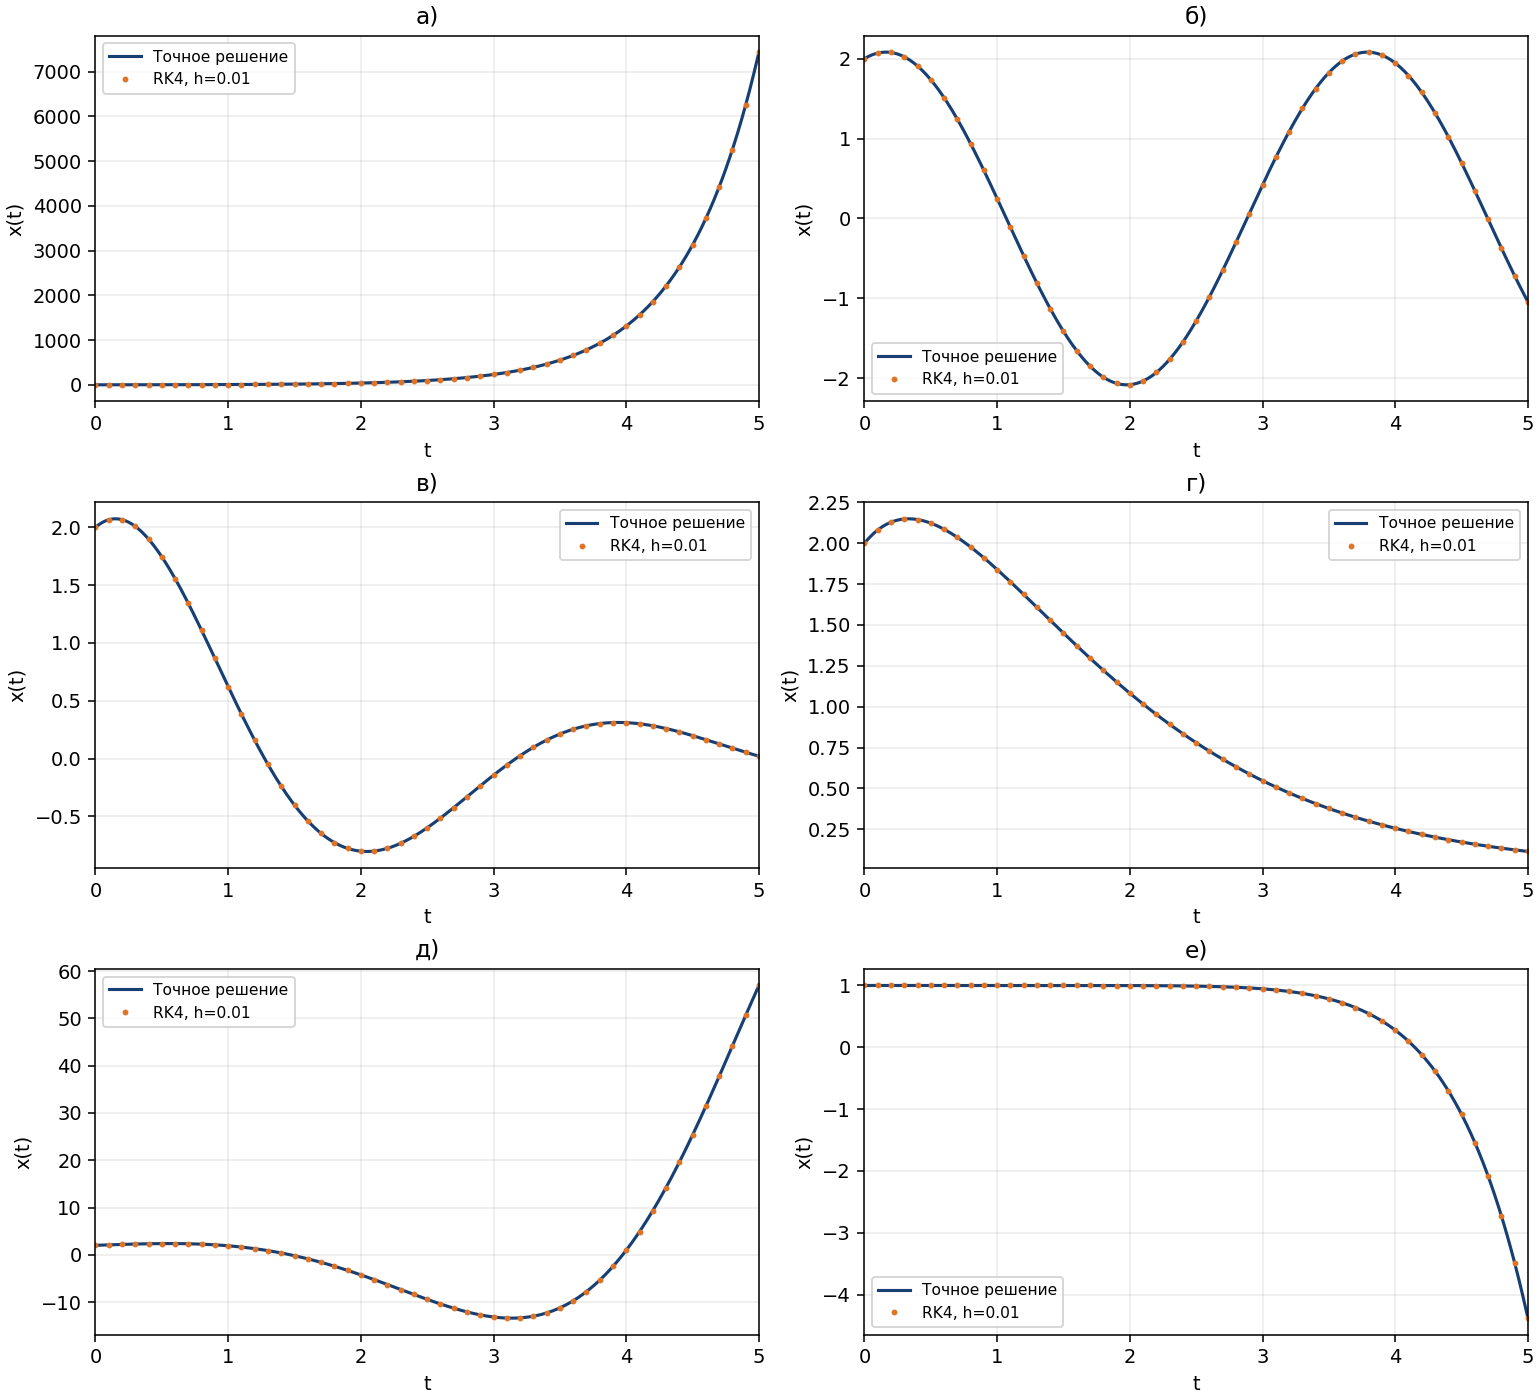

Максимальные абсолютные ошибки в узлах (независимый расчёт той же схемой RK4):

| Пример | Ошибка |
|---|---:|
| а | 4.760e-05 |
| б | 1.282e-08 |
| в | 2.221e-09 |
| г | 3.210e-10 |
| д | 5.155e-08 |
| е | 1.070e-08 |

Вывод: при шаге $0.01$ приближённые и точные кривые визуально совпадают во всех шести примерах. Наибольшая абсолютная ошибка — у быстро растущего решения а). Последние цифры ошибок при пересчёте могут отличаться из-за округления.